In [1]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import (
    LinearRegression, SGDRegressor, HuberRegressor, TheilSenRegressor, RANSACRegressor, QuantileRegressor
)
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR, LinearSVR, NuSVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels.csv', index_col='ID')
categorical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_categorical_features.csv', index_col='ID')
numerical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_numercial_features.csv', index_col='ID')

## 🛑 Task 2.4: Creatine

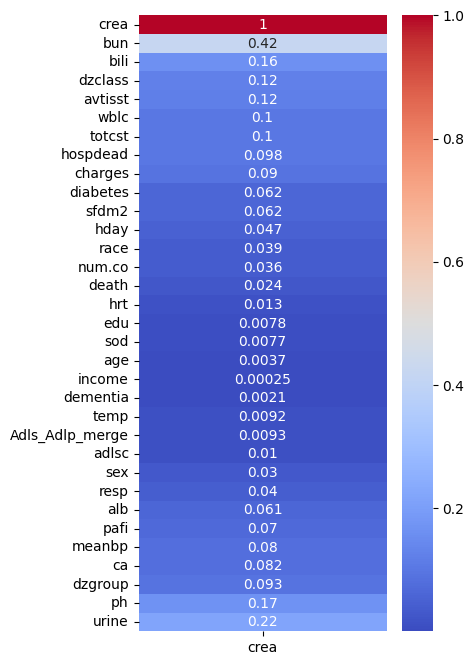

In [2]:
plt.figure(figsize=(4, 8))
sns.heatmap(df.corr()["crea"].sort_values(ascending=False).abs().to_frame(), annot=True, cmap='coolwarm')
plt.show()

The variables are not highly linearly correlated

### 🛑  Model Analysis

In [3]:
target=df['crea']
features=df.drop(['crea'],axis=1)
categorical_features_cols= categorical_features.columns
numerical_features_cols = numerical_features.columns.drop('crea').tolist()



In [4]:
# Definir StratifiedKFold (estratificando la variable objetivo discretizada)
bins = pd.qcut(target, q=5, labels=False)  # Discretizar en quintiles
kfold_external = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
data_dict = {}
# Crear un DataFrame para guardar resultados
evaluation_metrics_scaled = pd.DataFrame(columns=['Model', 'MAE_VAL', 'MAPE_VAL', 'RMSE_VAL', 'R2_VAL', 'R2_adjusted_VAL', 'MAE_TRAIN', 'MAPE_TRAIN', 'RMSE_TRAIN', 'R2_TRAIN', 'R2_adjusted_TRAIN'])

# Función para calcular métricas
def evaluate_model(y_true, y_pred, n, p):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)
    r2_adjusted = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
    return mae, mape, rmse, r2, r2_adjusted

# Modelos de regresión
models = {
    "Linear Regression": LinearRegression(),
    "Quantile Regression": QuantileRegressor(quantile=0.5),
    "Polynomial Regression (Degree=2)": Pipeline([
        ("poly_features", PolynomialFeatures(degree=2)),
        ("linear_regression", LinearRegression())
    ]),
    "Linear SVR": LinearSVR(random_state=42),
    "SVR": SVR(),
    "NuSVR": NuSVR(),
    "SGD Regression": SGDRegressor(random_state=42),
    "Nearest Neighbor Regression": KNeighborsRegressor(),
    "Decision Tree Regression": DecisionTreeRegressor(random_state=42),
    "RANSAC Regression": RANSACRegressor(random_state=42),
    "Theil-Sen Regression": TheilSenRegressor(random_state=42),
    "Huber Regressor": HuberRegressor()
}

for fold, (train_val_index, test_index) in enumerate(kfold_external.split(features, bins)):
    fold_external_dict = {}
    # Dividir en conjunto de prueba y conjunto de entrenamiento/validación
    X_train_val, X_test = features.iloc[train_val_index], features.iloc[test_index]
    y_train_val, y_test = target.iloc[train_val_index], target.iloc[test_index]
    
    # Índices alineados 
    bins_train_val = bins.iloc[train_val_index]
    
    # Inicialización de KFold interno
    kfold_internal = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
    number=1
    for train_index, val_index in kfold_internal.split(X_train_val, bins_train_val):
        # División en conjuntos de entrenamiento y validación
        X_train = X_train_val.iloc[train_index]
        y_train = y_train_val.iloc[train_index]
        X_val = X_train_val.iloc[val_index]
        y_val = y_train_val.iloc[val_index]

        # Separar variables cuantitativas y cualitativas
        X_train_quantitative = X_train[numerical_features_cols]
        X_val_quantitative = X_val[numerical_features_cols]
        X_test_quantitative = X_test[numerical_features_cols]
        X_train_qualitative = pd.get_dummies(X_train[categorical_features_cols], drop_first=True)
        X_val_qualitative = pd.get_dummies(X_val[categorical_features_cols], drop_first=True)
        X_test_qualitative = pd.get_dummies(X_test[categorical_features_cols], drop_first=True)
        
        # Normalizar datos
        # Initialize the scaler
        scaler = StandardScaler()

        # Fit and transform on the training data, preserving the index
        X_scaled_train = scaler.fit_transform(X_train_quantitative)
        X_scaled_train = pd.DataFrame(X_scaled_train, columns=X_train_quantitative.columns, index=X_train_quantitative.index)

        # Transform validation data (using the same scaler fitted on training data), preserving the index
        X_scaled_val = scaler.transform(X_val_quantitative)
        X_scaled_val = pd.DataFrame(X_scaled_val, columns=X_val_quantitative.columns, index=X_val_quantitative.index)

        # Transform test data (using the same scaler fitted on training data), preserving the index
        X_scaled_test = scaler.transform(X_test_quantitative)
        X_scaled_test = pd.DataFrame(X_scaled_test, columns=X_test_quantitative.columns, index=X_test_quantitative.index)

        X_scaled_train=pd.concat([X_scaled_train,X_train_qualitative],axis=1)
        X_scaled_val=pd.concat([X_scaled_val,X_val_qualitative],axis=1)
        X_scaled_test=pd.concat([X_scaled_test,X_test_qualitative],axis=1)

        # Guardar los datos procesados
        fold_internal_key = f'Fold_Interno_{number}'
        fold_external_dict[fold_internal_key] = {
            'Train_X': X_scaled_train,
            'Train_Y': y_train,
            'Validation_X': X_scaled_val,
            'Validation_Y': y_val,
            'Test_X': X_scaled_test,
            'Test_Y': y_test
        }

        # Guardar el fold externo con todos los internos
        fold_external_key = f'Fold_Externo_{fold}'
        data_dict[fold_external_key] = fold_external_dict

        for model_name, model in models.items():
            # Ajustar el modelo y realizar predicciones
            model.fit(X_scaled_train, y_train)
            y_pred = model.predict(X_scaled_val)

            # Calcular las métricas para el set de validación
            n, p = X_scaled_test.shape
            mae, mape, rmse, r2, r2_adjusted = evaluate_model(y_val, y_pred, n, p)

           

            # Calculando las métricas para el conjunto de train
            mae_train, mape_train, rmse_train, r2_train, r2_adjusted_train = evaluate_model(y_train, model.predict(X_scaled_train), n, p)

            # Registrar las métricas
            model_row = pd.DataFrame([{
                'Model': model_name,
                'MAE_VAL': mae,
                'MAPE_VAL': mape,
                'RMSE_VAL': rmse,
                'R2_VAL': r2,
                'R2_adjusted_VAL': r2_adjusted,
                'MAE_TRAIN': mae_train,
                'MAPE_TRAIN': mape_train,
                'RMSE_TRAIN': rmse_train,
                'R2_TRAIN': r2_train,
                'R2_adjusted_TRAIN': r2_adjusted_train

            }])
            evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)
        number=number+1

# Mostrar resultados finales
evaluation_metrics_scaled.head()

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_77449/1028027018.py:127: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/sv

,Model,MAE_VAL,MAPE_VAL,RMSE_VAL,R2_VAL,R2_adjusted_VAL,MAE_TRAIN,MAPE_TRAIN,RMSE_TRAIN,R2_TRAIN,R2_adjusted_TRAIN
0,Linear Regression,0.885812,60.802711,1.492801,0.221789,0.207386,0.866940,58.537531,1.461465,0.255390,0.241608
1,Quantile Regression,0.905802,44.692365,1.783212,-0.110451,-0.131003,0.917082,44.650975,1.788785,-0.115498,-0.136143
2,Polynomial Regression (Degree=2),1.003038,71.420711,1.598983,0.107144,0.090619,0.782899,55.506777,1.227401,0.474799,0.465079
3,Linear SVR,0.777327,40.572671,1.553545,0.157168,0.141569,0.773687,39.157653,1.542852,0.170148,0.154789
4,SVR,0.743306,39.945392,1.489707,0.225012,0.210668,0.641300,31.111961,1.403559,0.313227,0.300516


In [5]:
evaluation_metrics_scaled.groupby('Model').mean().sort_values('R2_adjusted_VAL', ascending=False)

,MAE_VAL,MAPE_VAL,RMSE_VAL,R2_VAL,R2_adjusted_VAL,MAE_TRAIN,MAPE_TRAIN,RMSE_TRAIN,R2_TRAIN,R2_adjusted_TRAIN
Model,,,,,,,,,,
Linear Regression,0.868793,58.605136,1.469787,0.232223,0.218011,8.603768e-01,5.809244e+01,1.454619e+00,0.248016,0.234097
NuSVR,0.744142,40.827618,1.473928,0.227994,0.213704,6.645778e-01,3.478176e+01,1.397048e+00,0.306368,0.293529
Theil-Sen Regression,0.832198,53.114046,1.479314,0.222293,0.207898,8.267782e-01,5.273901e+01,1.470144e+00,0.231929,0.217712
SGD Regression,0.861222,55.810443,1.483584,0.217754,0.203274,8.536235e-01,5.533307e+01,1.469528e+00,0.232433,0.218226
SVR,0.738545,38.377037,1.488326,0.212812,0.198241,6.375868e-01,3.055863e+01,1.410949e+00,0.292514,0.279418
Huber Regressor,0.769479,39.897281,1.533362,0.164507,0.149042,7.637042e-01,3.948737e+01,1.528118e+00,0.170113,0.154752
Linear SVR,0.770535,38.256083,1.551071,0.144932,0.129104,7.634173e-01,3.771198e+01,1.545872e+00,0.150746,0.135027
Nearest Neighbor Regression,0.887990,55.556003,1.589456,0.101331,0.084697,7.239370e-01,4.510575e+01,1.289363e+00,0.408870,0.397929
Polynomial Regression (Degree=2),0.984716,68.027830,1.643201,0.034213,0.016336,7.823320e-01,5.522507e+01,1.237702e+00,0.455184,0.445100


--- 
# ⭐️ GENERAL CONCLUSIONS BETTER MODEL DUE TO THEIR PERFORMANCE

# Comparative Analysis of Regression Models

## 1. **Overall Performance**
The overall performance of the models is moderate, with low \( R^2 \) values in both validation and training. Most models have **\( R^2 \)** below 0.3, indicating that they fail to capture much of the variability in the data.

---

## 2. **Best Models**
The models with **lower errors** and **better \( R^2 \)** values are:

- **SVR**  
  - **MAE_VAL**: 0.7385  
  - **RMSE_VAL**: 1.4883  
  - **R2_VAL**: 0.2128  

- **NuSVR**  
  - **MAE_VAL**: 0.7441  
  - **RMSE_VAL**: 1.4739  
  - **R2_VAL**: 0.2280  

- **Theil-Sen Regression**  
  - **MAE_VAL**: 0.8322  
  - **RMSE_VAL**: 1.4793  
  - **R2_VAL**: 0.2223  

These models have the best Mean Absolute Error (**MAE**) and Root Mean Squared Error (**RMSE**) values, with slightly positive **\( R^2 \)**, indicating some predictive ability.

---

## 3. **Worst Models**
The models with **higher errors** and negative \( R^2 \) values are:

- **RANSAC Regression**  
  - **MAE_VAL**: 1.7414  
  - **RMSE_VAL**: 2.7291  
  - **R2_VAL**: -1.8719  

- **Decision Tree Regression**  
  - **MAE_VAL**: 1.0225  
  - **RMSE_VAL**: 1.9088  
  - **R2_VAL**: -0.3042  

- **Quantile Regression**  
  - **MAE_VAL**: 0.9045  
  - **RMSE_VAL**: 1.7695  
  - **R2_VAL**: -0.1127  

These models have high prediction errors and **negative \( R^2 \)** values, meaning their performance is worse than a baseline model using the mean.

---

## 4. **Overfitting**
- **Decision Tree Regression** shows clear **overfitting**, as it has:  
  - **R2_TRAIN = 1.0** (perfect fit on training data).  
  - **R2_VAL = -0.3042** (poor performance on validation data).  

This suggests that the model memorizes the training data but fails to generalize to new data.

---

## 5. **Intermediate Models**
Models such as **Linear Regression**, **SGD Regression**, and **Huber Regressor** show moderate performance:

- **Linear Regression**  
  - **MAE_VAL**: 0.8688  
  - **RMSE_VAL**: 1.4698  
  - **R2_VAL**: 0.2322  

- **SGD Regression**  
  - **MAE_VAL**: 0.8612  
  - **RMSE_VAL**: 1.4836  
  - **R2_VAL**: 0.2178  

These models have reasonable error values but still low \( R^2 \).

---

## 6. **Conclusions**
1. **SVR** and **NuSVR** are the best-performing models, with the lowest validation errors and slightly positive \( R^2 \).  
2. **RANSAC Regression** and **Decision Tree Regression** perform poorly, with high errors and negative \( R^2 \).  
3. **Decision Tree Regression** suffers from severe overfitting.  
4. Further model tuning or alternative approaches (e.g., ensemble methods or feature engineering) are needed to improve performance.
